In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import tqdm
import seaborn as sns
from scipy.optimize import fsolve

In [19]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
TEs=df_TEs.index.values
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [27]:
df_temp = pd.read_excel('../../Data/SLCP_temps.xlsx',header=[0])
df_temp.head()
years = df_temp['year'].to_numpy()
no_years = len(years)
scenarios = ['combined','co2_only']

In [23]:
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df_temp[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df_temp[s].to_numpy()[t], T_lim, betas))

In [24]:
# ----------- SIMULATIONS ----------
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in (range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

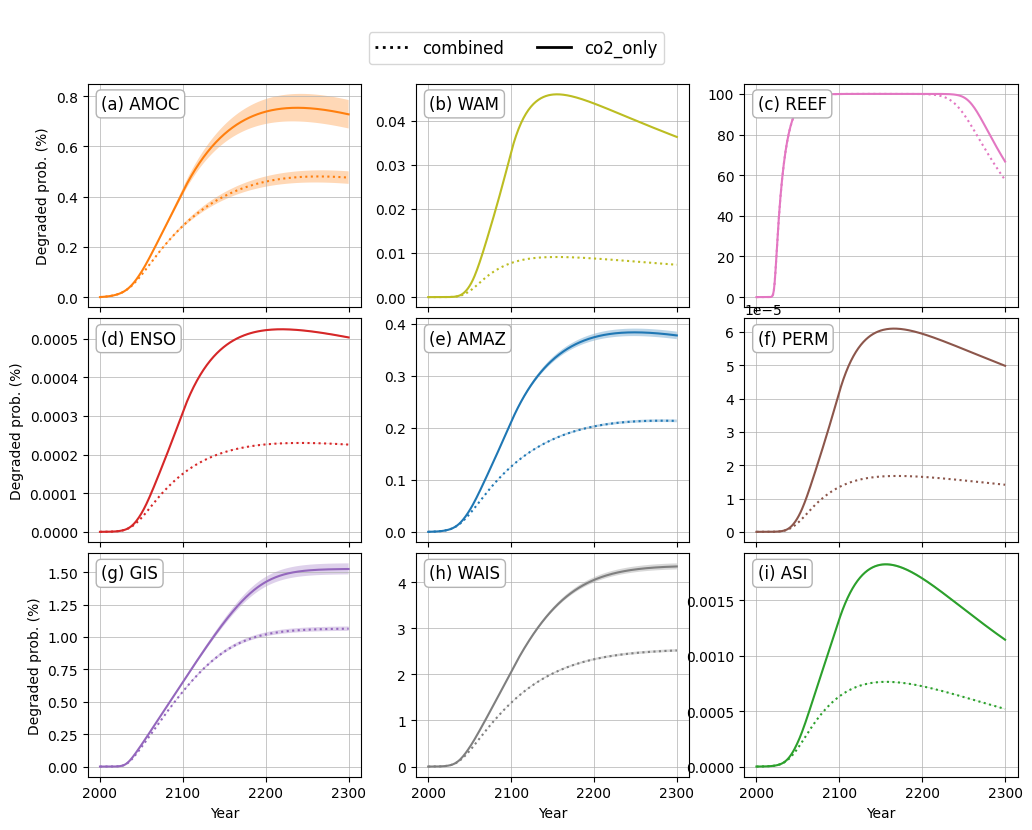

In [42]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
fig,axs = util.plot.TE_3x3_fig(TE_ordered=TE_ordered, subfig_lab_loc=[0.05,0.95],
                               ha='left',va='top',sharey=False)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':','-']
scen_labels = scenarios
TE_ind = {te:i for i,te in enumerate(TEs)}
ylims = [[-5,105]]*6+[[-.2,3.8], [-2,45], [-5,105]]
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j in range(len(scenarios)):
        util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], years, D[j,:,i,:]*100, color=colors[i],shade=[1],alpha=[0.3])
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    # axs[i_ax//3,i_ax%3].set_ylim(ylims[i_ax])
lines = [Line2D([0], [0], color=util.plot.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]
fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)

folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'individual_risk.png',format='png',dpi=300,bbox_inches='tight')

In [33]:
D.shape

(2, 500, 9, 301)

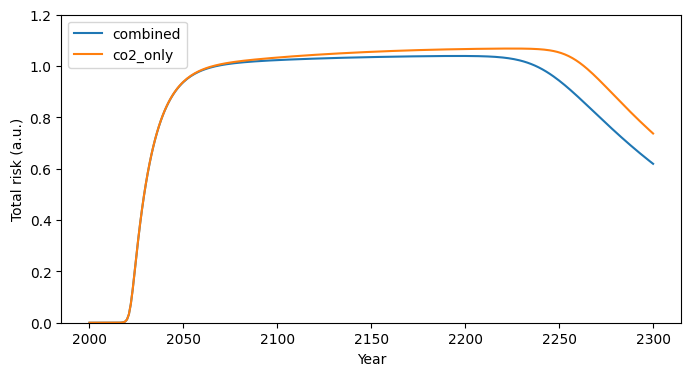

In [43]:
fig,ax = plt.subplots(figsize=(8,4))
for i,s in enumerate(scenarios):
    ax.plot(years,D[i,:,:,:].sum(axis=1).mean(axis=0),label=s)
ax.set_ylim([0,1.2])
ax.legend()
ax.set_ylabel('Total risk (a.u.)')
ax.set_xlabel('Year')
folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'total_risk.png',format='png',dpi=300,bbox_inches='tight')

In [60]:
D_ordered.shape

(9, 301)

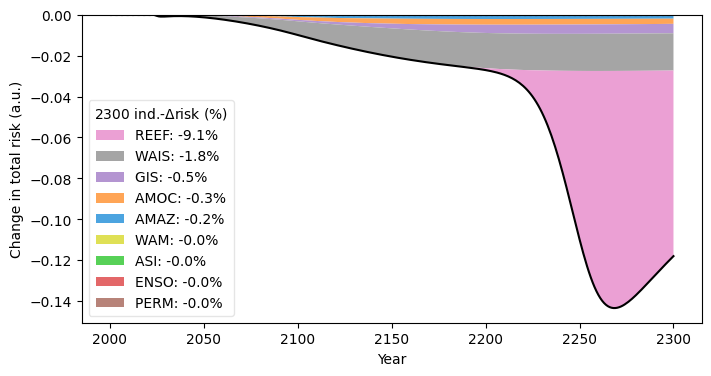

In [67]:
fig,ax = plt.subplots(figsize=(8,4))
ax.plot(years, (D[0,:,:,:]-D[1,:,:,:]).sum(axis=1).mean(axis=0),color='k')
ax.plot([2000,2300],[0,0],'k:')
order = (D[0,:,:,:]-D[1,:,:,:]).mean(axis=0)[:, -1].argsort()[::-1]
D_ordered = (D[0,:,:,:]-D[1,:,:,:]).mean(axis=0)[order]
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
ax.stackplot(years, D_ordered,zorder=1,
             colors = np.array([lighten_color(c,0.7)
                                for c in colors])[order],
             labels=np.array(TEs)[order])
ax.legend(loc='lower left',title='2300')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[::-1],
          labels=[l + ": {:.1f}%".format(D_ordered[i,-1]*100) for i,l in enumerate(labels)][::-1],
          # title=scenarios[scen_ind] + ': Final risks',
          ncols=1,loc='lower left',
          framealpha=0.5,title=r'2300 ind.-$\Delta$risk (%)')
ax.set_ylabel('Change in total risk (a.u.)')
ax.set_xlabel('Year')
folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'delta_risk_breakdown.png',format='png',dpi=300,bbox_inches='tight')

In [46]:
np.diff(D,axis=0).shape

(1, 500, 9, 301)